In [11]:
import pickle
import numpy as np
import pandas as pd
from pyhere import here
import matplotlib.pyplot as plt
from ratio_function import RatioGenerator, LogRatioGenerator
import itertools
from plotnine import *
from sklearn.model_selection import train_test_split
from sklearn import set_config
from skopt import BayesSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from catboost import CatBoostRegressor
from xgboost import XGBRegressor
from xgboost import plot_importance
from sklearn.svm import SVR
from skopt.space import Categorical, Real, Integer
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import cross_val_score, cross_validate, KFold
from sklearn.metrics import root_mean_squared_error, r2_score
from sklearn.base import clone
from sklearn.inspection import permutation_importance
import re

set_config(transform_output="pandas")

In [12]:
phot = pd.read_csv(here("data/cleaned", "MIRION_cleaned_everything.csv"))

flux_cols = ['F8', 'F12', 'F24', 'F70', 'F160', 'F250', 'F350', 'F500', 'F870', 'F1100']

model_pipe = Pipeline([
        ('impute', SimpleImputer()),
        ('ratio', RatioGenerator(cols=flux_cols)),
        ('scale', RobustScaler()),
        ('model', 'passthrough')
    ])

remove_properties = ['LRATIO', 'T_BOL', 'LM', 'L_BOL', 'MASS', 'DIAM', 'SURF_DENS', 'YB', 'TEMP']

# remove the reponses to contain only the physical properties
X = phot.drop(columns=remove_properties)

for wavelength in ['8', '12', '24', '70']:
    X[f'se_F{wavelength}'] = X[f'e_F{wavelength}'] / np.sqrt(X[f'N{wavelength}'])
    X= X.drop(columns =[f'e_F{wavelength}', f'N{wavelength}'])

error_thresholds = {'LRATIO': 4.85, 'T_BOL': 1.6, 'LM': 4.35, 'L_BOL': 1.6, 'MASS': 1.85, 'DIAM': 2.1, 'SURF_DENS': 4.6, 'TEMP': 1.6}



In [15]:
print(X.columns)

Index(['F8', 'F12', 'F24', 'F70', 'F160', 'e_F160', 'F250', 'e_F250', 'F350',
       'e_F350', 'F500', 'e_F500', 'F870', 'e_F870', 'F1100', 'e_F1100',
       'DIST', 'f_MULTI', 'f_CEXT', 'se_F8', 'se_F12', 'se_F24', 'se_F70'],
      dtype='str')


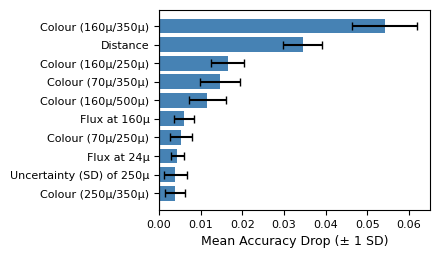

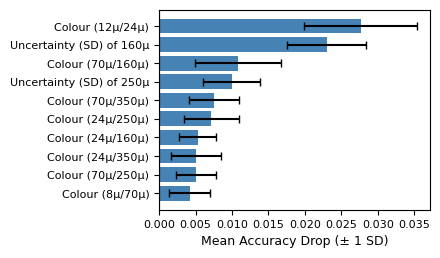

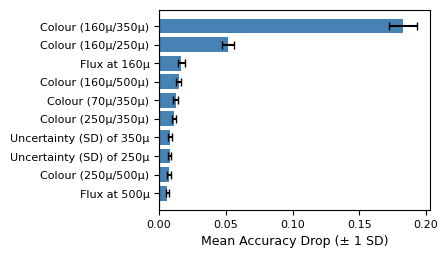

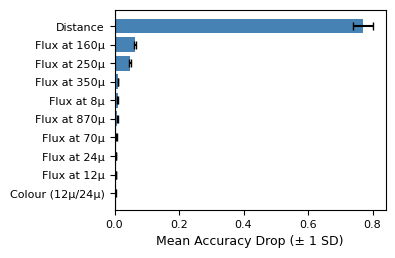

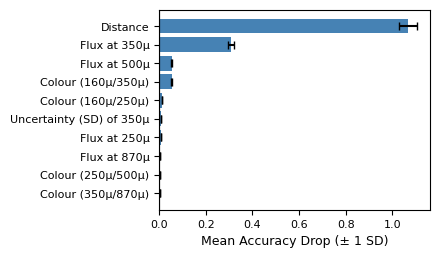

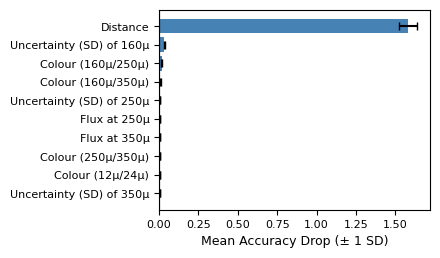

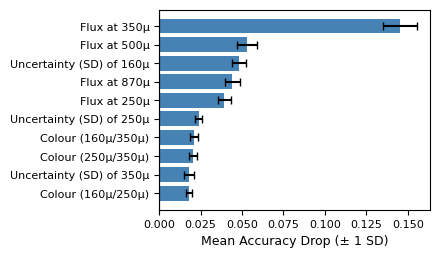

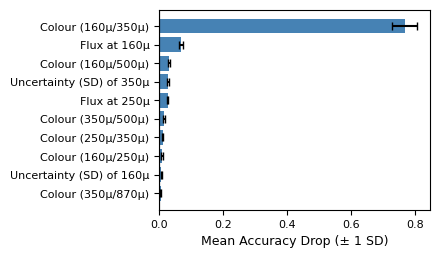

In [ ]:
properties = ['LRATIO', 'T_BOL', 'LM', 'L_BOL', 'MASS', 'DIAM', 'SURF_DENS', 'TEMP']
for property in properties:

    with open(here("models/full_models/6-20-26_best_skopt_models", f"{property}_results.pkl"), 'rb') as file:
        results = pickle.load(file)

    if property == 'TEMP' or property == 'T_BOL':
        y = phot[property]
    else:
        y = np.log(phot[property])

    X_threshold = X.copy()

    for wavelength in ['8', '12', '24', '70']:
        X_threshold.loc[X_threshold[f'se_F{wavelength}'] > error_thresholds[property], f'F{wavelength}'] = np.nan

    X_train, X_test, y_train, y_test = train_test_split(X_threshold, y, test_size = 0.2, random_state=2026)

    model_pipe_in_use = clone(model_pipe)
    catboost_model = CatBoostRegressor(random_state=2026, verbose=0, thread_count=-1, loss_function='RMSE')
    tuned_model = model_pipe_in_use.set_params(model=catboost_model)

    if property == 'TEMP' or property == 'T_BOL':
        tuned_model.set_params(**results['cat_params'])    
    else:
        tuned_model.set_params(**results['cat_log_params'])

    tuned_model.fit(X_train, y_train)
    y_preds = tuned_model.predict(X_test)

    perm_values = permutation_importance(
    tuned_model, X_test, y_test,
    n_repeats=10, random_state=2026, n_jobs=-1
    )

    perm_df = pd.DataFrame({
        'feature': X_test.columns,
        'mean': perm_values.importances_mean,
        'std':  perm_values.importances_std
    })

    name_map_large = {
        'F8': 'Flux at 8µ', 
        'F12': 'Flux at 12µ', 
        'F24': 'Flux at 24µ', 
        'F70': 'Flux at 70µ', 
        'F160': 'Flux at 160µ', 
        'e_F160': 'Uncertainty (SD) of 160µ', 
        'F250': 'Flux at 250µ', 
        'e_F250': 'Uncertainty (SD) of 250µ', 
        'F350': 'Flux at 350µ',
       'e_F350': 'Uncertainty (SD) of 350µ', 
       'F500': 'Flux at 500µ', 
       'e_F500': 'Uncertainty (SD) of 500µ', 
       'F870': 'Flux at 870µ', 
       'e_F870': 'Uncertainty (SD) of 870µ', 
       'F1100': 'Flux at 1100µ', 
       'e_F1100': 'Uncertainty (SD) of 1100µ',
       'DIST': 'Distance', 
       'f_MULTI': 'Multi-Source Flag', 
       'f_CEXT': 'Highly Circular Flag', 
       'se_F8': 'Uncertainty (SE) of 8µ', 
       'se_F12': 'Uncertainty (SE) of 12µ', 
       'se_F24': 'Uncertainty (SD) of 24µ', 
       'se_F70': 'Uncertainty (SD) of 70µ'
    }

    perm_df['feature'] = perm_df['feature'].map(name_map_large)
    perm_df = perm_df.sort_values('mean', ascending=False).head(10)

    fig, ax = plt.subplots(figsize=(3.5, 2.6))
    ax.barh(perm_df['feature'][::-1], perm_df['mean'][::-1],
            xerr=perm_df['std'][::-1], color='steelblue', capsize=3)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_xlabel('Mean Accuracy Drop (± 1 SD)', fontsize=9)
    # ax.set_title(f'Permutation Importance — {property} (top 15)')
    ax.tick_params(labelsize=8)
    plt.savefig(here('graphing/perm_imp_graphs/for_paper', f'{property}_no_ratios_new.pdf'), bbox_inches='tight')
    plt.close(fig)

    phot_for_perm = X.copy()
    for top, bottom in itertools.combinations(flux_cols, 2):
        new_col_name = f"log_{top}_over_{bottom}"
        phot_for_perm[new_col_name] = np.log(phot_for_perm[top] / phot_for_perm[bottom])
    perm_lrat_X_train, perm_lrat_X_test, perm_lrat_y_train, perm_lrat_y_test = train_test_split(phot_for_perm, y, test_size = 0.2, random_state=2026)
    perm_pipe = Pipeline([
        ('impute', SimpleImputer()),
        ('scale', RobustScaler()),
        ('model', 'passthrough')
    ])
    model = CatBoostRegressor(random_state=2026, verbose=0, thread_count=-1, loss_function='RMSE')
    perm_pipe.set_params(model=model)

    if property == 'TEMP' or property == 'T_BOL':
        if 'ratio' in results['cat_params']:
            del results['cat_params']['ratio']
        perm_pipe.set_params(**results['cat_params'])
    else:
        if 'ratio' in results['cat_log_params']:
            del results['cat_log_params']['ratio']
        perm_pipe.set_params(**results['cat_log_params'])

    perm_pipe.fit(perm_lrat_X_train, perm_lrat_y_train)
    perm_lrat_with_ratios = permutation_importance(
        perm_pipe, perm_lrat_X_test, perm_lrat_y_test,
        n_repeats=10, random_state=2026, n_jobs=-1
    )
    perm_lrat_ratios_df = pd.DataFrame({
        'feature': perm_lrat_X_test.columns,
        'mean': perm_lrat_with_ratios.importances_mean,
        'std':  perm_lrat_with_ratios.importances_std
    })

    name_map_larger = {}
    for feature in perm_lrat_ratios_df['feature'].unique():
        if re.search(r"F\d+", feature):
            wavelength = re.search(r'\d+', feature).group()
            new_feature = f"Flux at {wavelength}µ"
        if re.search(r'se_', feature):
            wavelength = re.search(r'\d+', feature).group()
            new_feature = f"Uncertainty (SE) of {wavelength}µ"
        if re.search(r'D', feature):
            new_feature = "Distance"
        if re.search(r'(?<!s)e_', feature):
            wavelength = re.search(r'\d+', feature).group()
            new_feature = f"Uncertainty (SD) of {wavelength}µ"
        if re.search(r'f_', feature):
            if re.search(r'f_M', feature):
                new_feature = 'Multi-Source Flag'
            if re.search(r'f_C', feature):
                new_feature = 'Highly Circular Flag'
        if re.search(r'log_',feature):
            numbers = re.compile(r'\d+')
            wavelengths = numbers.findall(feature)
            new_feature = f"Colour ({wavelengths[0]}µ/{wavelengths[1]}µ)"
        name_map_larger[feature] = new_feature
        
    perm_lrat_ratios_df['feature'] = perm_lrat_ratios_df['feature'].map(name_map_larger)
    perm_lrat_ratios_df= perm_lrat_ratios_df.sort_values('mean', ascending=False).head(10)

    fig, ax = plt.subplots(figsize=(3.5, 2.6))
    ax.barh(perm_lrat_ratios_df['feature'][::-1], perm_lrat_ratios_df['mean'][::-1],
            xerr=perm_lrat_ratios_df['std'][::-1], color='steelblue', capsize=3)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_xlabel('Mean Accuracy Drop (± 1 SD)', fontsize=9)
    # ax.set_title(f'Permutation Importance With Ratios — {property} (top 15)')
    ax.tick_params(labelsize=8)
    plt.savefig(here('graphing/perm_imp_graphs/for_paper', f'{property}_with_ratios_new.pdf'), bbox_inches='tight')

Now, this will be for baseline models:

In [4]:
properties = ['LRATIO']
for property in properties:

    with open(here("models/predictive_models/results", f"{property}_final_predictive_models.pkl"), 'rb') as file:
        results = pickle.load(file)

print(results)

{'best_quantile_error': -0.16089920748163902, 'best_quantile_params': {'error_threshold': 2.6, 'scalers': 'standard', 'ratios': 'norm_ratio', 'imputers': 'median', 'n_estimators': 1750, 'learning_rate': 0.005702808748129885, 'max_depth': 3, 'min_child_weight': 6, 'subsample': 0.9, 'colsample_bytree': 0.8, 'colsample_bylevel': 1.0, 'reg_alpha': 0.08544436579847664, 'reg_lambda': 2.419277708822829e-06, 'gamma': 1.5155984928220948e-06}, 'best_mean_error': -1.032798286899563, 'best_mean_params': {'error_threshold': 4.85, 'scalers': 'standard', 'ratios': 'norm_ratio', 'imputers': 'median', 'n_estimators': 2050, 'learning_rate': 0.003078967214304464, 'max_depth': 4, 'min_child_weight': 10, 'subsample': 0.9, 'colsample_bytree': 0.9, 'colsample_bylevel': 0.8, 'reg_alpha': 5.879802149885816e-05, 'reg_lambda': 0.0033440181467403666, 'gamma': 2.955215600426458e-06}}


In [ ]:
properties = ['LRATIO', 'T_BOL', 'LM', 'L_BOL', 'MASS', 'DIAM', 'SURF_DENS', 'TEMP']
for property in properties:

    with open(here("models/predictive_models/results", f"{property}_final_predictive_models.pkl"), 'rb') as file:
        results = pickle.load(file)

    if property == 'TEMP' or property == 'T_BOL':
        y = phot[property]
    else:
        y = np.log(phot[property])

    mean_params = results['best_mean_params']
    scalers = mean_params.pop('scalers')
    ratios = mean_params.pop('ratios')
    imputers = mean_params.pop('imputers')
    error_threshold = mean_params.pop('error_threshold')
    
    if scalers == "standard":
        scaler = StandardScaler()
    elif scalers == 'robust':
        scaler = RobustScaler()
    else:
        scaler = 'passthrough'

    if ratios == 'norm_ratio':
        ratio = RatioGenerator(cols=flux_cols)
    else:
        ratio = LogRatioGenerator(cols=flux_cols)

    if imputers == 'mean':
        imputer = SimpleImputer(strategy='mean')
    elif imputers == 'median': 
        imputer = SimpleImputer(strategy='median')
    else:
        imputer = 'passthrough'

    X_threshold = X.copy()
        
    for wavelength in ['8', '12', '24', '70']:
        X_threshold.loc[X_threshold[f'se_F{wavelength}'] > error_threshold, f'F{wavelength}'] = np.nan

    X_train, X_test, y_train, y_test = train_test_split(X_threshold, y, test_size = 0.2, random_state=2026)

    model_pipe_in_use = clone(model_pipe)
    xgboost_model = XGBRegressor()
    tuned_model = model_pipe_in_use.set_params(model=xgboost_model)

    tuned_model.fit(X_train, y_train)
    y_preds = tuned_model.predict(X_test)

    perm_values = permutation_importance(
    tuned_model, X_test, y_test,
    n_repeats=10, random_state=2026, n_jobs=-1
    )

    perm_df = pd.DataFrame({
        'feature': X_test.columns,
        'mean': perm_values.importances_mean,
        'std':  perm_values.importances_std
    })

    name_map_large = {
        'F8': 'Flux at 8µ', 
        'F12': 'Flux at 12µ', 
        'F24': 'Flux at 24µ', 
        'F70': 'Flux at 70µ', 
        'F160': 'Flux at 160µ', 
        'e_F160': 'Uncertainty (SD) of 160µ', 
        'F250': 'Flux at 250µ', 
        'e_F250': 'Uncertainty (SD) of 250µ', 
        'F350': 'Flux at 350µ',
       'e_F350': 'Uncertainty (SD) of 350µ', 
       'F500': 'Flux at 500µ', 
       'e_F500': 'Uncertainty (SD) of 500µ', 
       'F870': 'Flux at 870µ', 
       'e_F870': 'Uncertainty (SD) of 870µ', 
       'F1100': 'Flux at 1100µ', 
       'e_F1100': 'Uncertainty (SD) of 1100µ',
       'DIST': 'Distance', 
       'f_MULTI': 'Multi-Source Flag', 
       'f_CEXT': 'Highly Circular Flag', 
       'se_F8': 'Uncertainty (SE) of 8µ', 
       'se_F12': 'Uncertainty (SE) of 12µ', 
       'se_F24': 'Uncertainty (SD) of 24µ', 
       'se_F70': 'Uncertainty (SD) of 70µ'
    }

    perm_df['feature'] = perm_df['feature'].map(name_map_large)
    perm_df = perm_df.sort_values('mean', ascending=False).head(10)

    fig, ax = plt.subplots(figsize=(3.5, 2.6))
    ax.barh(perm_df['feature'][::-1], perm_df['mean'][::-1],
            xerr=perm_df['std'][::-1], color='steelblue', capsize=3)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_xlabel('Mean Accuracy Drop (± 1 SD)', fontsize=9)
    # ax.set_title(f'Permutation Importance — {property} (top 15)')
    ax.tick_params(labelsize=8)
    plt.savefig(here('graphing/perm_imp_graphs/for_paper', f'{property}_no_ratios_new.pdf'), bbox_inches='tight')
    plt.close(fig)

    phot_for_perm = X.copy()
    for top, bottom in itertools.combinations(flux_cols, 2):
        new_col_name = f"log_{top}_over_{bottom}"
        phot_for_perm[new_col_name] = np.log(phot_for_perm[top] / phot_for_perm[bottom])
    perm_lrat_X_train, perm_lrat_X_test, perm_lrat_y_train, perm_lrat_y_test = train_test_split(phot_for_perm, y, test_size = 0.2, random_state=2026)
    perm_pipe = Pipeline([
        ('impute', SimpleImputer()),
        ('scale', RobustScaler()),
        ('model', 'passthrough')
    ])
    model = CatBoostRegressor(random_state=2026, verbose=0, thread_count=-1, loss_function='RMSE')
    perm_pipe.set_params(model=model)

    if property == 'TEMP' or property == 'T_BOL':
        if 'ratio' in results['cat_params']:
            del results['cat_params']['ratio']
        perm_pipe.set_params(**results['cat_params'])
    else:
        if 'ratio' in results['cat_log_params']:
            del results['cat_log_params']['ratio']
        perm_pipe.set_params(**results['cat_log_params'])

    perm_pipe.fit(perm_lrat_X_train, perm_lrat_y_train)
    perm_lrat_with_ratios = permutation_importance(
        perm_pipe, perm_lrat_X_test, perm_lrat_y_test,
        n_repeats=10, random_state=2026, n_jobs=-1
    )
    perm_lrat_ratios_df = pd.DataFrame({
        'feature': perm_lrat_X_test.columns,
        'mean': perm_lrat_with_ratios.importances_mean,
        'std':  perm_lrat_with_ratios.importances_std
    })

    name_map_larger = {}
    for feature in perm_lrat_ratios_df['feature'].unique():
        if re.search(r"F\d+", feature):
            wavelength = re.search(r'\d+', feature).group()
            new_feature = f"Flux at {wavelength}µ"
        if re.search(r'se_', feature):
            wavelength = re.search(r'\d+', feature).group()
            new_feature = f"Uncertainty (SE) of {wavelength}µ"
        if re.search(r'D', feature):
            new_feature = "Distance"
        if re.search(r'(?<!s)e_', feature):
            wavelength = re.search(r'\d+', feature).group()
            new_feature = f"Uncertainty (SD) of {wavelength}µ"
        if re.search(r'f_', feature):
            if re.search(r'f_M', feature):
                new_feature = 'Multi-Source Flag'
            if re.search(r'f_C', feature):
                new_feature = 'Highly Circular Flag'
        if re.search(r'log_',feature):
            numbers = re.compile(r'\d+')
            wavelengths = numbers.findall(feature)
            new_feature = f"Colour ({wavelengths[0]}µ/{wavelengths[1]}µ)"
        name_map_larger[feature] = new_feature
        
    perm_lrat_ratios_df['feature'] = perm_lrat_ratios_df['feature'].map(name_map_larger)
    perm_lrat_ratios_df= perm_lrat_ratios_df.sort_values('mean', ascending=False).head(10)

    fig, ax = plt.subplots(figsize=(3.5, 2.6))
    ax.barh(perm_lrat_ratios_df['feature'][::-1], perm_lrat_ratios_df['mean'][::-1],
            xerr=perm_lrat_ratios_df['std'][::-1], color='steelblue', capsize=3)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_xlabel('Mean Accuracy Drop (± 1 SD)', fontsize=9)
    # ax.set_title(f'Permutation Importance With Ratios — {property} (top 15)')
    ax.tick_params(labelsize=8)
    plt.savefig(here('graphing/perm_imp_graphs/for_paper', f'{property}_with_ratios_new.pdf'), bbox_inches='tight')

In [ ]:
print(perm_df)

   feature      mean       std
4     F160  4.135149  0.106980
8     F350  1.294621  0.033130
10    F500  0.113010  0.007968
6     F250  0.110142  0.012089
12    F870  0.031237  0.005313
9   e_F350  0.027249  0.003935
5   e_F160  0.006882  0.001883
2      F24  0.002840  0.000590
7   e_F250  0.002264  0.001152
13  e_F870  0.001743  0.000444
0       F8  0.001710  0.002053
1      F12  0.001575  0.000488
3      F70  0.001417  0.001070
11  e_F500  0.000901  0.003433
20  se_F12  0.000603  0.000308


testing other graphing types of permutation improtance graphs

C:\Users\alexe\AppData\Local\Temp\ipykernel_31400\522452433.py:70: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
C:\Users\alexe\AppData\Local\Temp\ipykernel_31400\522452433.py:143: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
C:\Users\alexe\AppData\Local\Temp\ipykernel_31400\522452433.py:70: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
C:\Users\alexe\AppData\Local\Temp\ipykernel_31400\522452433.py:143: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
C:\Users\alexe\AppData\Local\Temp\ipykernel_31400\5224

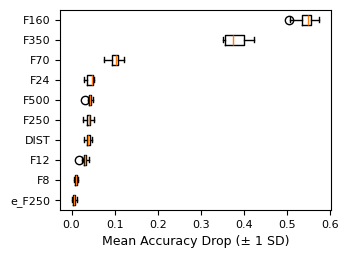

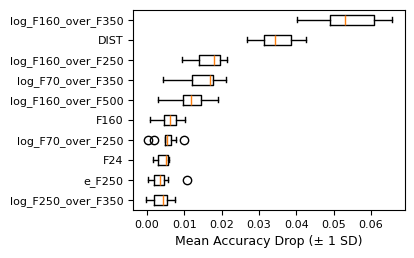

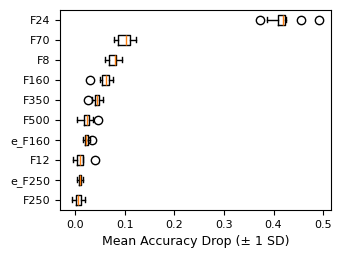

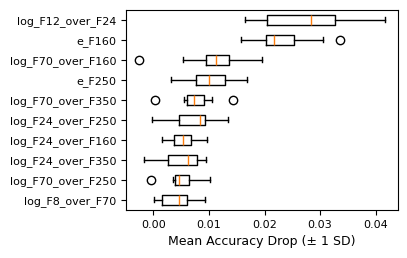

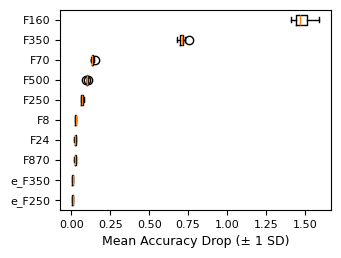

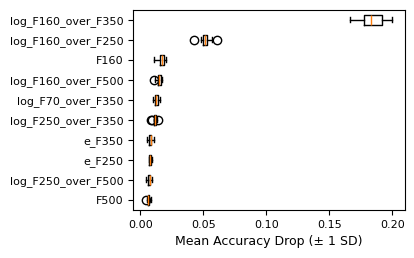

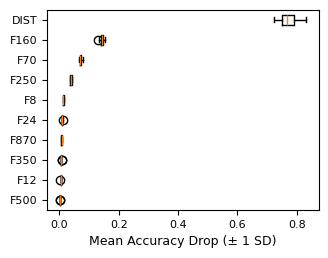

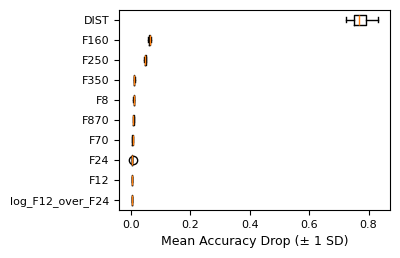

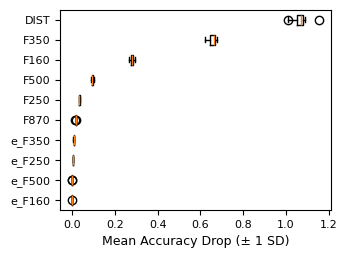

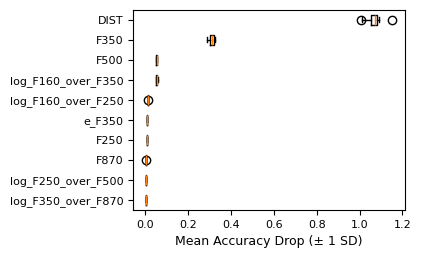

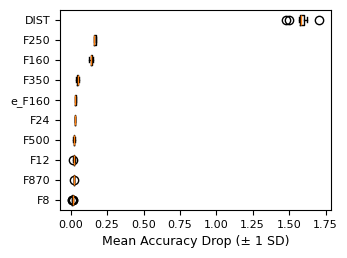

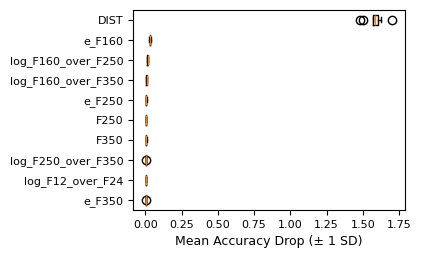

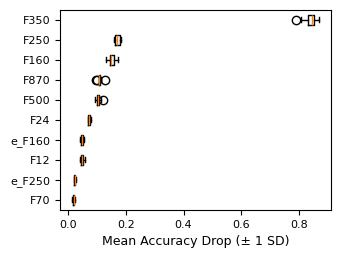

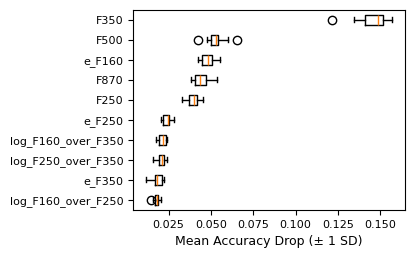

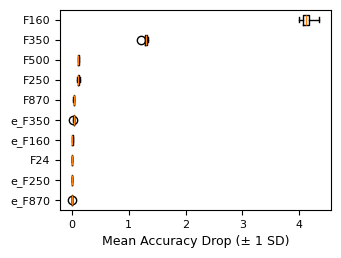

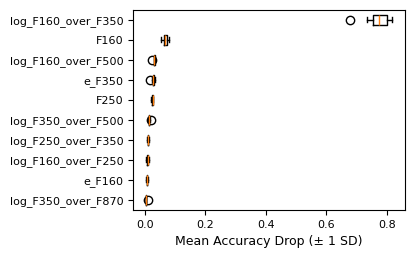

In [3]:
properties = ['LRATIO', 'T_BOL', 'LM', 'L_BOL', 'MASS', 'DIAM', 'SURF_DENS', 'TEMP']
for property in properties:

    with open(here("models/full_models/6-20-26_best_skopt_models", f"{property}_results.pkl"), 'rb') as file:
        results = pickle.load(file)

    if property == 'TEMP' or property == 'T_BOL':
        y = phot[property]
    else:
        y = np.log(phot[property])

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state=2026)

    model_pipe_in_use = clone(model_pipe)
    catboost_model = CatBoostRegressor(random_state=2026, verbose=0, thread_count=-1, loss_function='RMSE')
    tuned_model = model_pipe_in_use.set_params(model=catboost_model)

    if property == 'TEMP' or property == 'T_BOL':
        tuned_model.set_params(**results['cat_params'])    
    else:
        tuned_model.set_params(**results['cat_log_params'])

    tuned_model.fit(X_train, y_train)
    y_preds = tuned_model.predict(X_test)

    perm_values = permutation_importance(
    tuned_model, X_test, y_test,
    n_repeats=10, random_state=2026, n_jobs=-1
    )

    # perm_df = pd.DataFrame({
    #     'feature': X_test.columns,
    #     'mean': perm_values.importances_mean,
    #     'std':  perm_values.importances_std,
    #     'repeats': perm_values.importances
    # })

    name_map_large = {
        'F8': 'Flux at 8µ', 
        'F12': 'Flux at 12µ', 
        'F24': 'Flux at 24µ', 
        'F70': 'Flux at 70µ', 
        'F160': 'Flux at 160µ', 
        'e_F160': 'Uncertainty (SD) of 160µ', 
        'F250': 'Flux at 250µ', 
        'e_F250': 'Uncertainty (SD) of 250µ', 
        'F350': 'Flux at 350µ',
       'e_F350': 'Uncertainty (SD) of 350µ', 
       'F500': 'Flux at 500µ', 
       'e_F500': 'Uncertainty (SD) of 500µ', 
       'F870': 'Flux at 870µ', 
       'e_F870': 'Uncertainty (SD) of 870µ', 
       'F1100': 'Flux at 1100µ', 
       'e_F1100': 'Uncertainty (SD) of 1100µ',
       'DIST': 'Distance', 
       'f_MULTI': 'Multi-Source Flag', 
       'f_CEXT': 'Highly Circular Flag', 
       'se_F8': 'Uncertainty (SE) of 8µ', 
       'se_F12': 'Uncertainty (SE) of 12µ', 
       'se_F24': 'Uncertainty (SD) of 24µ', 
       'se_F70': 'Uncertainty (SD) of 70µ'
    }

    sorted_idx = perm_values.importances_mean.argsort()[-10:]

    # perm_df['feature'] = perm_df['feature'].map(name_map_large)
    # perm_df = perm_df.sort_values('mean', ascending=False).head(10)

    fig, ax = plt.subplots(figsize=(3.5, 2.6))
    ax.boxplot(perm_values.importances[sorted_idx].T, vert=False,
    labels=np.array(X_test.columns)[sorted_idx])
    #ax.axvline(0, color='black', linewidth=0.8)
    ax.set_xlabel('Mean Accuracy Drop (± 1 SD)', fontsize=9)
    # ax.set_title(f'Permutation Importance — {property} (top 15)')
    ax.tick_params(labelsize=8)
    # plt.savefig(here('graphing/perm_imp_graphs/for_paper', f'{property}_no_ratios_new.pdf'), bbox_inches='tight')
    # plt.close(fig)

    phot_for_perm = X.copy()
    for top, bottom in itertools.combinations(flux_cols, 2):
        new_col_name = f"log_{top}_over_{bottom}"
        phot_for_perm[new_col_name] = np.log(phot_for_perm[top] / phot_for_perm[bottom])
    perm_lrat_X_train, perm_lrat_X_test, perm_lrat_y_train, perm_lrat_y_test = train_test_split(phot_for_perm, y, test_size = 0.2, random_state=2026)
    perm_pipe = Pipeline([
        ('impute', SimpleImputer()),
        ('scale', RobustScaler()),
        ('model', 'passthrough')
    ])
    model = CatBoostRegressor(random_state=2026, verbose=0, thread_count=-1, loss_function='RMSE')
    perm_pipe.set_params(model=model)

    if property == 'TEMP' or property == 'T_BOL':
        if 'ratio' in results['cat_params']:
            del results['cat_params']['ratio']
        perm_pipe.set_params(**results['cat_params'])
    else:
        if 'ratio' in results['cat_log_params']:
            del results['cat_log_params']['ratio']
        perm_pipe.set_params(**results['cat_log_params'])

    perm_pipe.fit(perm_lrat_X_train, perm_lrat_y_train)
    perm_lrat_with_ratios = permutation_importance(
        perm_pipe, perm_lrat_X_test, perm_lrat_y_test,
        n_repeats=10, random_state=2026, n_jobs=-1
    )
    # perm_lrat_ratios_df = pd.DataFrame({
    #     'feature': perm_lrat_X_test.columns,
    #     'mean': perm_lrat_with_ratios.importances_mean,
    #     'std':  perm_lrat_with_ratios.importances_std,
    #     'repeats': perm_lrat_with_ratios.importances
    # })

    name_map_larger = {}
    # for feature in perm_lrat_ratios_df['feature'].unique():
    #     if re.search(r"F\d+", feature):
    #         wavelength = re.search(r'\d+', feature).group()
    #         new_feature = f"Flux at {wavelength}µ"
    #     if re.search(r'se_', feature):
    #         wavelength = re.search(r'\d+', feature).group()
    #         new_feature = f"Uncertainty (SE) of {wavelength}µ"
    #     if re.search(r'D', feature):
    #         new_feature = "Distance"
    #     if re.search(r'(?<!s)e_', feature):
    #         wavelength = re.search(r'\d+', feature).group()
    #         new_feature = f"Uncertainty (SD) of {wavelength}µ"
    #     if re.search(r'f_', feature):
    #         if re.search(r'f_M', feature):
    #             new_feature = 'Multi-Source Flag'
    #         if re.search(r'f_C', feature):
    #             new_feature = 'Highly Circular Flag'
    #     if re.search(r'log_',feature):
    #         numbers = re.compile(r'\d+')
    #         wavelengths = numbers.findall(feature)
    #         new_feature = f"Colour ({wavelengths[0]}µ/{wavelengths[1]}µ)"
    #     name_map_larger[feature] = new_feature
        
    # perm_lrat_ratios_df['feature'] = perm_lrat_ratios_df['feature'].map(name_map_larger)
    # perm_lrat_ratios_df= perm_lrat_ratios_df.sort_values('mean', ascending=False).head(10)

    sorted_idx = perm_lrat_with_ratios.importances_mean.argsort()[-10:]

    fig, ax = plt.subplots(figsize=(3.5, 2.6))
    ax.boxplot(perm_lrat_with_ratios.importances[sorted_idx].T, vert=False,
            labels=np.array(perm_lrat_X_test.columns)[sorted_idx])
    ax.set_xlabel('Mean Accuracy Drop (± 1 SD)', fontsize=9)
    # ax.set_title(f'Permutation Importance With Ratios — {property} (top 15)')
    ax.tick_params(labelsize=8)
    # plt.savefig(here('graphing/perm_imp_graphs/for_paper', f'{property}_with_ratios_new.pdf'), bbox_inches='tight')

plt.show()

In [7]:
with open(here("models/full_models/6-20-26_best_skopt_models", "LRATIO_results.pkl"), 'rb') as file:
    results = pickle.load(file)
results

{'cat_CV': np.float64(177.31765039260944),
 'cat_params': OrderedDict([('impute', KNNImputer()),
              ('model__bagging_temperature', 0.5270568209177788),
              ('model__border_count', 32),
              ('model__colsample_bylevel', 0.05564335212893637),
              ('model__depth', 12),
              ('model__grow_policy', 'Lossguide'),
              ('model__iterations', 3000),
              ('model__l2_leaf_reg', 100.0),
              ('model__learning_rate', 0.01059045317396377),
              ('model__min_data_in_leaf', 1),
              ('model__random_strength', 10.0),
              ('ratio',
               LogRatioGenerator(cols=['F8', 'F12', 'F24', 'F70', 'F160', 'F250', 'F350',
                                       'F500', 'F870', 'F1100'])),
              ('scale', 'passthrough')]),
 'cat_log_CV': np.float64(0.8750611991203785),
 'cat_log_params': OrderedDict([('impute', SimpleImputer()),
              ('model__bagging_temperature', 9.662514272906984),
   

In [15]:
properties = ['LRATIO', 'T_BOL', 'LM', 'L_BOL', 'MASS', 'DIAM', 'SURF_DENS', 'TEMP']
for property in properties:

    with open(here("models/full_models/6-20-26_best_skopt_models", f"{property}_results.pkl"), 'rb') as file:
        results = pickle.load(file)

    if property == 'TEMP' or property == 'T_BOL':
        y = phot[property]
    else:
        y = np.log(phot[property])

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state=2026)

    model_pipe_in_use = clone(model_pipe)
    catboost_model = CatBoostRegressor(random_state=2026, verbose=0, thread_count=-1, loss_function='RMSE')
    model_pipe_in_use.set_params(model=catboost_model)

    if property == 'TEMP' or property == 'T_BOL':
        model_pipe_in_use.set_params(**results['cat_params'])    
    else:
        model_pipe_in_use.set_params(**results['cat_log_params'])

    model_pipe_in_use.fit(X_train, y_train)
    y_preds = model_pipe_in_use.predict(X_test)

    perm_values = permutation_importance(
    model_pipe_in_use, X_test, y_test,
    n_repeats=10, random_state=2026, n_jobs=-1
    )

    # perm_df = pd.DataFrame({
    #     'feature': X_test.columns,
    #     'mean': perm_values.importances_mean,
    #     'std':  perm_values.importances_std,
    #     'repeats': perm_values.importances
    # })

    name_map_large = {
        'F8': 'Flux at 8µ', 
        'F12': 'Flux at 12µ', 
        'F24': 'Flux at 24µ', 
        'F70': 'Flux at 70µ', 
        'F160': 'Flux at 160µ', 
        'e_F160': 'σ of 160µ', 
        'F250': 'Flux at 250µ', 
        'e_F250': 'σ of 250µ', 
        'F350': 'Flux at 350µ',
       'e_F350': 'σ of 350µ', 
       'F500': 'Flux at 500µ', 
       'e_F500': 'σ of 500µ', 
       'F870': 'Flux at 870µ', 
       'e_F870': 'σ of 870µ', 
       'F1100': 'Flux at 1100µ', 
       'e_F1100': 'σ of 1100µ',
       'DIST': 'Distance', 
       'f_MULTI': 'Multi-Source Flag', 
       'f_CEXT': 'Highly Circular Flag', 
       'se_F8': 'SE of 8µ', 
       'se_F12': 'SE of 12µ', 
       'se_F24': 'SD of 24µ', 
       'se_F70': 'SD of 70µ'
    }

    sorted_idx = perm_values.importances_mean.argsort()[-8:]

    # perm_df['feature'] = perm_df['feature'].map(name_map_large)
    # perm_df = perm_df.sort_values('mean', ascending=False).head(10)

    fig, ax = plt.subplots(figsize=(3.5, 2.6))

    for i, feature_idx in enumerate(sorted_idx):
        importances = perm_values.importances[feature_idx]
        
        # Plot each individual repeat as a dot aligned on the horizontal row y = i
        ax.scatter(importances, np.full_like(importances, i), alpha=0.6, s=50, edgecolors="w", zorder=2, color="steelblue")
        
        # Plot the mean as a red diamond marker for quick reference
        mean_val = perm_values.importances_mean[feature_idx]
        ax.scatter([mean_val], [i], color="black", marker="|", s=70, zorder=3, label="Mean" if i == sorted_idx[-1] else "")

        low_val = min(perm_values.importances[feature_idx])
        ax.scatter([low_val], [i], color="steelblue", marker="|", s=70, zorder=3)

        high_val = max(perm_values.importances[feature_idx])
        ax.scatter([high_val], [i], color="steelblue", marker="|", s=70, zorder=3)

        ax.set_yticks(range(len(sorted_idx)))
        ax.set_yticklabels(np.array(X_test.columns.map(name_map_large))[sorted_idx])
        # ax.set_title("Top 10 Permutation Importances (Dot Plot)")
        ax.xaxis.set_label_coords(0.25, -0.15)
        ax.set_xlabel("Mean Accuracy Drop (± 1 SD)")
        ax.legend(loc="lower right")
        plt.tight_layout()
    
    plt.savefig(here('graphing/perm_imp_graphs/for_paper/paper_perm_imp_graphs', f'{property}_no_ratios.pdf'), bbox_inches='tight')
    plt.close(fig)

    phot_for_perm = X.copy()
    for top, bottom in itertools.combinations(flux_cols, 2):
        new_col_name = f"log_{top}_over_{bottom}"
        phot_for_perm[new_col_name] = np.log(phot_for_perm[top] / phot_for_perm[bottom])
    perm_lrat_X_train, perm_lrat_X_test, perm_lrat_y_train, perm_lrat_y_test = train_test_split(phot_for_perm, y, test_size = 0.2, random_state=2026)
    perm_pipe = Pipeline([
        ('impute', SimpleImputer()),
        ('scale', RobustScaler()),
        ('model', 'passthrough')
    ])
    model = CatBoostRegressor(random_state=2026, verbose=0, thread_count=-1, loss_function='RMSE')
    perm_pipe.set_params(model=model)

    if property == 'TEMP' or property == 'T_BOL':
        if 'ratio' in results['cat_params']:
            del results['cat_params']['ratio']
        perm_pipe.set_params(**results['cat_params'])
    else:
        if 'ratio' in results['cat_log_params']:
            del results['cat_log_params']['ratio']
        perm_pipe.set_params(**results['cat_log_params'])

    perm_pipe.fit(perm_lrat_X_train, perm_lrat_y_train)
    perm_lrat_with_ratios = permutation_importance(
        perm_pipe, perm_lrat_X_test, perm_lrat_y_test,
        n_repeats=10, random_state=2026, n_jobs=-1
    )
    # perm_lrat_ratios_df = pd.DataFrame({
    #     'feature': perm_lrat_X_test.columns,
    #     'mean': perm_lrat_with_ratios.importances_mean,
    #     'std':  perm_lrat_with_ratios.importances_std,
    #     'repeats': perm_lrat_with_ratios.importances
    # })

    name_map_larger = {}
    for feature in perm_lrat_X_test.columns:
        if re.search(r"F\d+", feature):
            wavelength = re.search(r'\d+', feature).group()
            new_feature = f"Flux at {wavelength}µ"
        if re.search(r'se_', feature):
            wavelength = re.search(r'\d+', feature).group()
            new_feature = f"SE of {wavelength}µ"
        if re.search(r'D', feature):
            new_feature = "Distance"
        if re.search(r'(?<!s)e_', feature):
            wavelength = re.search(r'\d+', feature).group()
            new_feature = f"σ of {wavelength}µ"
        if re.search(r'f_', feature):
            if re.search(r'f_M', feature):
                new_feature = 'Multi-Source Flag'
            if re.search(r'f_C', feature):
                new_feature = 'Highly Circular Flag'
        if re.search(r'log_',feature):
            numbers = re.compile(r'\d+')
            wavelengths = numbers.findall(feature)
            new_feature = f"Colour ({wavelengths[0]}µ/{wavelengths[1]}µ)"
        name_map_larger[feature] = new_feature
        
    # perm_lrat_ratios_df['feature'] = perm_lrat_ratios_df['feature'].map(name_map_larger)
    # perm_lrat_ratios_df= perm_lrat_ratios_df.sort_values('mean', ascending=False).head(10)

    sorted_idx = perm_lrat_with_ratios.importances_mean.argsort()[-8:]
    var = 0

    fig, ax = plt.subplots(figsize=(3.5, 2.6))
    for i, feature_idx in enumerate(sorted_idx):
        importances = perm_lrat_with_ratios.importances[feature_idx]
        
        # Plot each individual repeat as a dot aligned on the horizontal row y = i
        ax.scatter(importances, np.full_like(importances, i), alpha=0.6, s=50, edgecolors="w", zorder=2, color='steelblue')
        
        # Plot the mean
        mean_val = perm_lrat_with_ratios.importances_mean[feature_idx]

        if var == 0:
            ax.scatter([mean_val], [i], color="black", marker="|", s=70, zorder=3, label="Mean")
            var +=1
        else:
            ax.scatter([mean_val], [i], color="black", marker="|", s=70, zorder=3, label="")

        low_val = min(perm_lrat_with_ratios.importances[feature_idx])
        ax.scatter([low_val], [i], color="steelblue", marker="|", s=70, zorder=3)

        high_val = max(perm_lrat_with_ratios.importances[feature_idx])
        ax.scatter([high_val], [i], color="steelblue", marker="|", s=70, zorder=3)

        ax.set_yticks(range(len(sorted_idx)))
        ax.set_yticklabels(np.array(perm_lrat_X_test.columns.map(name_map_larger))[sorted_idx])
        # ax.set_title("Top 10 Permutation Importances (Dot Plot)")
        ax.set_xlabel("Mean Accuracy Drop", loc='left')
        ax.legend(loc="lower right")
    plt.savefig(here('graphing/perm_imp_graphs/for_paper/paper_perm_imp_graphs', f'{property}_with_ratios.pdf'), bbox_inches='tight')
    plt.close(fig)

plt.show()

C:\Users\alexe\AppData\Local\Temp\ipykernel_22908\2321640844.py:92: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
C:\Users\alexe\AppData\Local\Temp\ipykernel_22908\2321640844.py:92: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
C:\Users\alexe\AppData\Local\Temp\ipykernel_22908\2321640844.py:92: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
C:\Users\alexe\AppData\Local\Temp\ipykernel_22908\2321640844.py:92: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
C:\Users\alexe\AppData\Local\Temp\ipykernel_2290

CatBoostError: (Error 1224: The requested operation cannot be performed on a file with a user-mapped section open.) util/system/file.cpp:936: can't open "catboost_info\\learn\\events.out.tfevents" with mode WrOnly|CreateAlways|Seq (0x00000034)

In [21]:
for property in ['TEMP']:    
    with open(here("models/full_models/6-20-26_best_skopt_models", f"{property}_results.pkl"), 'rb') as file:
            results = pickle.load(file)
    
    y = phot[property]

    phot_for_perm = X.copy()
    for top, bottom in itertools.combinations(flux_cols, 2):
        new_col_name = f"log_{top}_over_{bottom}"
        phot_for_perm[new_col_name] = np.log(phot_for_perm[top] / phot_for_perm[bottom])
    perm_lrat_X_train, perm_lrat_X_test, perm_lrat_y_train, perm_lrat_y_test = train_test_split(phot_for_perm, y, test_size = 0.2, random_state=2026)
    perm_pipe = Pipeline([
        ('impute', SimpleImputer()),
        ('scale', RobustScaler()),
        ('model', 'passthrough')
    ])
    model = CatBoostRegressor(random_state=2026, verbose=0, thread_count=-1, loss_function='RMSE')
    perm_pipe.set_params(model=model)

    if property == 'TEMP' or property == 'T_BOL':
        if 'ratio' in results['cat_params']:
            del results['cat_params']['ratio']
        perm_pipe.set_params(**results['cat_params'])
    else:
        if 'ratio' in results['cat_log_params']:
            del results['cat_log_params']['ratio']
        perm_pipe.set_params(**results['cat_log_params'])

    perm_pipe.fit(perm_lrat_X_train, perm_lrat_y_train)
    perm_lrat_with_ratios = permutation_importance(
        perm_pipe, perm_lrat_X_test, perm_lrat_y_test,
        n_repeats=10, random_state=2026, n_jobs=-1
    )
    # perm_lrat_ratios_df = pd.DataFrame({
    #     'feature': perm_lrat_X_test.columns,
    #     'mean': perm_lrat_with_ratios.importances_mean,
    #     'std':  perm_lrat_with_ratios.importances_std,
    #     'repeats': perm_lrat_with_ratios.importances
    # })

    name_map_larger = {}
    for feature in perm_lrat_X_test.columns:
        if re.search(r"F\d+", feature):
            wavelength = re.search(r'\d+', feature).group()
            new_feature = f"Flux at {wavelength}µ"
        if re.search(r'se_', feature):
            wavelength = re.search(r'\d+', feature).group()
            new_feature = f"SE of {wavelength}µ"
        if re.search(r'D', feature):
            new_feature = "Distance"
        if re.search(r'(?<!s)e_', feature):
            wavelength = re.search(r'\d+', feature).group()
            new_feature = f"σ of {wavelength}µ"
        if re.search(r'f_', feature):
            if re.search(r'f_M', feature):
                new_feature = 'Multi-Source Flag'
            if re.search(r'f_C', feature):
                new_feature = 'Highly Circular Flag'
        if re.search(r'log_',feature):
            numbers = re.compile(r'\d+')
            wavelengths = numbers.findall(feature)
            new_feature = f"Colour ({wavelengths[0]}µ/{wavelengths[1]}µ)"
        name_map_larger[feature] = new_feature
        
    # perm_lrat_ratios_df['feature'] = perm_lrat_ratios_df['feature'].map(name_map_larger)
    # perm_lrat_ratios_df= perm_lrat_ratios_df.sort_values('mean', ascending=False).head(10)

    sorted_idx = perm_lrat_with_ratios.importances_mean.argsort()[-8:]
    var = 0

    fig, ax = plt.subplots(figsize=(3.5, 2.6))
    for i, feature_idx in enumerate(sorted_idx):
        importances = perm_lrat_with_ratios.importances[feature_idx]
        
        # Plot each individual repeat as a dot aligned on the horizontal row y = i
        ax.scatter(importances, np.full_like(importances, i), alpha=0.6, s=50, edgecolors="w", zorder=2, color='steelblue')
        
        # Plot the mean
        mean_val = perm_lrat_with_ratios.importances_mean[feature_idx]

        if var == 0:
            ax.scatter([mean_val], [i], color="black", marker="|", s=70, zorder=3, label="Mean")
            var +=1
        else:
            ax.scatter([mean_val], [i], color="black", marker="|", s=70, zorder=3, label="")

        low_val = min(perm_lrat_with_ratios.importances[feature_idx])
        ax.scatter([low_val], [i], color="steelblue", marker="|", s=70, zorder=3)

        high_val = max(perm_lrat_with_ratios.importances[feature_idx])
        ax.scatter([high_val], [i], color="steelblue", marker="|", s=70, zorder=3)

        ax.set_yticks(range(len(sorted_idx)))
        ax.set_yticklabels(np.array(perm_lrat_X_test.columns.map(name_map_larger))[sorted_idx])
        # ax.set_title("Top 10 Permutation Importances (Dot Plot)")
        ax.set_xlabel("Mean Accuracy Drop", loc='left')
        ax.legend(loc="lower right")
    plt.savefig(here('graphing/perm_imp_graphs/for_paper/paper_perm_imp_graphs', f'{property}_with_ratios.pdf'), bbox_inches='tight')
    plt.close(fig)

plt.show()

In [16]:
with open(here("models/predictive_models/results", "LRATIO_final_predictive_models.pkl"), 'rb') as file:
        results = pickle.load(file)
print(results)

{'best_quantile_error': -0.16089920748163902, 'best_quantile_params': {'error_threshold': 2.6, 'scalers': 'standard', 'ratios': 'norm_ratio', 'imputers': 'median', 'n_estimators': 1750, 'learning_rate': 0.005702808748129885, 'max_depth': 3, 'min_child_weight': 6, 'subsample': 0.9, 'colsample_bytree': 0.8, 'colsample_bylevel': 1.0, 'reg_alpha': 0.08544436579847664, 'reg_lambda': 2.419277708822829e-06, 'gamma': 1.5155984928220948e-06}, 'best_mean_error': -1.032798286899563, 'best_mean_params': {'error_threshold': 4.85, 'scalers': 'standard', 'ratios': 'norm_ratio', 'imputers': 'median', 'n_estimators': 2050, 'learning_rate': 0.003078967214304464, 'max_depth': 4, 'min_child_weight': 10, 'subsample': 0.9, 'colsample_bytree': 0.9, 'colsample_bylevel': 0.8, 'reg_alpha': 5.879802149885816e-05, 'reg_lambda': 0.0033440181467403666, 'gamma': 2.955215600426458e-06}}


In [20]:
X_lowflux = phot[['F8','e_F8','F12','e_F12','F24','e_F24','F70','e_F70','N8', 'N12', 'N24', "N70", "DIST", 'f_MULTI','f_CEXT']]

for wavelength in ['8', '12', '24', '70']:
    X_lowflux[f'se_F{wavelength}'] = X_lowflux[f'e_F{wavelength}'] / np.sqrt(X_lowflux[f'N{wavelength}'])
    X_lowflux= X_lowflux.drop(columns =[f'e_F{wavelength}', f'N{wavelength}'])

flux_cols = ['F8', 'F12', 'F24', 'F70']

properties = ['LRATIO', 'T_BOL', 'LM', 'L_BOL', 'MASS', 'DIAM', 'SURF_DENS', 'TEMP']
for property in properties:

    with open(here("models/predictive_models/results", f"{property}_final_predictive_models.pkl"), 'rb') as file:
        results = pickle.load(file)

    if property == 'TEMP' or property == 'T_BOL':
        y = phot[property]
    else:
        y = np.log(phot[property])

    mean_params = results['best_mean_params']
    scalers = mean_params.pop('scalers')
    ratios = mean_params.pop('ratios')
    imputers = mean_params.pop('imputers')
    error_threshold = mean_params.pop('error_threshold')
    
    if scalers == "standard":
        scaler = StandardScaler()
    elif scalers == 'robust':
        scaler = RobustScaler()
    else:
        scaler = 'passthrough'

    if ratios == 'norm_ratio':
        ratio = RatioGenerator(cols=flux_cols)
    else:
        ratio = LogRatioGenerator(cols=flux_cols)

    if imputers == 'mean':
        imputer = SimpleImputer(strategy='mean')
    elif imputers == 'median': 
        imputer = SimpleImputer(strategy='median')
    else:
        imputer = 'passthrough'

    X_threshold = X_lowflux.copy()
        
    for wavelength in ['8', '12', '24', '70']:
        X_threshold.loc[X_threshold[f'se_F{wavelength}'] > error_threshold, f'F{wavelength}'] = np.nan

    X_train, X_test, y_train, y_test = train_test_split(X_threshold, y, test_size = 0.2, random_state=2026)

    xgboost_model = XGBRegressor(**mean_params)
    model_pipe = make_pipeline(imputer, ratio, scaler, xgboost_model)
    model_pipe.fit(X_train, y_train)

    model_pipe.fit(X_train, y_train)
    y_preds = model_pipe.predict(X_test)

    perm_values = permutation_importance(
    model_pipe, X_test, y_test,
    n_repeats=10, random_state=2026, n_jobs=-1
    )

    # perm_df = pd.DataFrame({
    #     'feature': X_test.columns,
    #     'mean': perm_values.importances_mean,
    #     'std':  perm_values.importances_std
    # })

    name_map_large = {
            'F8': 'Flux at 8µ', 
            'F12': 'Flux at 12µ', 
            'F24': 'Flux at 24µ', 
            'F70': 'Flux at 70µ', 
            'F160': 'Flux at 160µ', 
            'DIST': 'Distance', 
            'f_MULTI': 'Multi-Source Flag', 
            'f_CEXT': 'Highly Circular Flag', 
            'se_F8': 'SE of 8µ', 
            'se_F12': 'SE of 12µ', 
            'se_F24': 'SE of 24µ', 
            'se_F70': 'SE of 70µ'
        }

    sorted_idx = perm_values.importances_mean.argsort()[-8:]

    # perm_df['feature'] = perm_df['feature'].map(name_map_large)
    # perm_df = perm_df.sort_values('mean', ascending=False).head(10)

    fig, ax = plt.subplots(figsize=(3.5, 2.6))

    for i, feature_idx in enumerate(sorted_idx):
        importances = perm_values.importances[feature_idx]
        
        # Plot each individual repeat as a dot aligned on the horizontal row y = i
        ax.scatter(importances, np.full_like(importances, i), alpha=0.6, s=50, edgecolors="w", zorder=2, color="steelblue")
        
        # Plot the mean as a red diamond marker for quick reference
        mean_val = perm_values.importances_mean[feature_idx]
        ax.scatter([mean_val], [i], color="black", marker="|", s=70, zorder=3, label="Mean" if i == sorted_idx[-1] else "")

        low_val = min(perm_values.importances[feature_idx])
        ax.scatter([low_val], [i], color="steelblue", marker="|", s=70, zorder=3)

        high_val = max(perm_values.importances[feature_idx])
        ax.scatter([high_val], [i], color="steelblue", marker="|", s=70, zorder=3)

        ax.set_yticks(range(len(sorted_idx)))
        ax.set_yticklabels(np.array(X_test.columns.map(name_map_large))[sorted_idx])
        # ax.set_title("Top 10 Permutation Importances (Dot Plot)")
        ax.xaxis.set_label_coords(0.25, -0.15)
        ax.set_xlabel("Mean Accuracy Drop")
        ax.legend(loc="lower right")
        plt.tight_layout()

    plt.savefig(here('graphing/perm_imp_graphs/for_paper/paper_perm_imp_graphs', f'{property}_lowflux_no_ratios.pdf'), bbox_inches='tight')
    plt.close(fig)
    plt.show()


    phot_for_perm = X_lowflux.copy()
    for top, bottom in itertools.combinations(flux_cols, 2):
        new_col_name = f"log_{top}_over_{bottom}"
        phot_for_perm[new_col_name] = np.log(phot_for_perm[top] / phot_for_perm[bottom])

    if scalers == "standard":
        scaler = StandardScaler()
    elif scalers == 'robust':
        scaler = RobustScaler()
    else:
        scaler = 'passthrough'

    if ratios == 'norm_ratio':
        ratio = RatioGenerator(cols=flux_cols)
    else:
        ratio = LogRatioGenerator(cols=flux_cols)

    if imputers == 'mean':
        imputer = SimpleImputer(strategy='mean')
    elif imputers == 'median': 
        imputer = SimpleImputer(strategy='median')
    else:
        imputer = 'passthrough'
        
    for wavelength in ['8', '12', '24', '70']:
        phot_for_perm.loc[phot_for_perm[f'se_F{wavelength}'] > error_threshold, f'F{wavelength}'] = np.nan

    perm_lrat_X_train, perm_lrat_X_test, perm_lrat_y_train, perm_lrat_y_test = train_test_split(phot_for_perm, y, test_size = 0.2, random_state=2026)

    xgboost_model = XGBRegressor(**mean_params)
    perm_pipe = make_pipeline(imputer, ratio, scaler, xgboost_model)
    perm_pipe.fit(perm_lrat_X_train, perm_lrat_y_train)

    y_preds = perm_pipe.predict(perm_lrat_X_test)
    
    perm_lrat_with_ratios = permutation_importance(
        perm_pipe, perm_lrat_X_test, perm_lrat_y_test,
        n_repeats=10, random_state=2026, n_jobs=-1
    )
    # perm_lrat_ratios_df = pd.DataFrame({
    #     'feature': perm_lrat_X_test.columns,
    #     'mean': perm_lrat_with_ratios.importances_mean,
    #     'std':  perm_lrat_with_ratios.importances_std
    # })

    name_map_larger = {}
    for feature in perm_lrat_X_test.columns:
        if re.search(r"F\d+", feature):
            wavelength = re.search(r'\d+', feature).group()
            new_feature = f"Flux at {wavelength}µ"
        if re.search(r'se_', feature):
            wavelength = re.search(r'\d+', feature).group()
            new_feature = f"SE of {wavelength}µ"
        if re.search(r'D', feature):
            new_feature = "Distance"
        if re.search(r'(?<!s)e_', feature):
            wavelength = re.search(r'\d+', feature).group()
            new_feature = f"σ of {wavelength}µ"
        if re.search(r'f_', feature):
            if re.search(r'f_M', feature):
                new_feature = 'Multi-Source Flag'
            if re.search(r'f_C', feature):
                new_feature = 'Highly Circular Flag'
        if re.search(r'log_',feature):
            numbers = re.compile(r'\d+')
            wavelengths = numbers.findall(feature)
            new_feature = f"Colour ({wavelengths[0]}µ/{wavelengths[1]}µ)"
        name_map_larger[feature] = new_feature

    sorted_idx = perm_lrat_with_ratios.importances_mean.argsort()[-8:]
    var = 0

    fig, ax = plt.subplots(figsize=(3.5, 2.6))
    for i, feature_idx in enumerate(sorted_idx):
        importances = perm_lrat_with_ratios.importances[feature_idx]
        
        # Plot each individual repeat as a dot aligned on the horizontal row y = i
        ax.scatter(importances, np.full_like(importances, i), alpha=0.6, s=50, edgecolors="w", zorder=2, color='steelblue')
        
        # Plot the mean
        mean_val = perm_lrat_with_ratios.importances_mean[feature_idx]

        if var == 0:
            ax.scatter([mean_val], [i], color="black", marker="|", s=70, zorder=3, label="Mean")
            var +=1
        else:
            ax.scatter([mean_val], [i], color="black", marker="|", s=70, zorder=3, label="")

        low_val = min(perm_lrat_with_ratios.importances[feature_idx])
        ax.scatter([low_val], [i], color="steelblue", marker="|", s=70, zorder=3)

        high_val = max(perm_lrat_with_ratios.importances[feature_idx])
        ax.scatter([high_val], [i], color="steelblue", marker="|", s=70, zorder=3)

        ax.set_yticks(range(len(sorted_idx)))
        ax.set_yticklabels(np.array(perm_lrat_X_test.columns.map(name_map_larger))[sorted_idx])
        # ax.set_title("Top 10 Permutation Importances (Dot Plot)")
        ax.set_xlabel("Mean Accuracy Drop", loc='left')
        ax.legend(loc="lower right")
    plt.savefig(here('graphing/perm_imp_graphs/for_paper/paper_perm_imp_graphs', f'{property}_lowflux_with_ratios.pdf'), bbox_inches='tight')
    plt.close(fig)
    plt.show()


C:\Users\alexe\AppData\Local\Temp\ipykernel_22908\2123532119.py:113: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
C:\Users\alexe\AppData\Local\Temp\ipykernel_22908\2123532119.py:113: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
C:\Users\alexe\AppData\Local\Temp\ipykernel_22908\2123532119.py:113: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
C:\Users\alexe\AppData\Local\Temp\ipykernel_22908\2123532119.py:113: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
C:\Users\alexe\AppData\Local\Temp\ipykernel_